# From Demand Forecasting to Operational Optimization

### Objective

This project aims to demonstrate an end-to-end analytics workflow
that transforms historical demand data into actionable operational
decisions.

The workflow combines:

- Data analytics
- Statistical analysis
- Machine learning
- Operations research
- Optimization
- Scenario simulation
- Data visualization

### Business Problem

How can historical bike-sharing demand data be used to forecast
future demand and support operational capacity planning under
limited resources and uncertain demand conditions?

### Analytical Approach

The project follows a structured workflow:

1. Understand the business problem and dataset.
2. Assess data quality and prepare the data.
3. Perform exploratory and statistical analysis.
4. Develop demand forecasting models.
5. Optimize operational capacity allocation.
6. Evaluate optimization performance.
7. Test sensitivity and robustness.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

DATA_DIR = Path(".")

hour_path = DATA_DIR / "hour.csv"
day_path = DATA_DIR / "day.csv"

if not hour_path.exists():
    raise FileNotFoundError(
        f"hour.csv not found at: {hour_path.resolve()}"
    )

df = pd.read_csv(hour_path)

print(f"Dataset loaded successfully.")
print(f"Number of rows: {df.shape[0]:,}")
print(f"Number of columns: {df.shape[1]}")

Dataset loaded successfully.
Number of rows: 17,379
Number of columns: 17


In [2]:
df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


In [3]:
df.tail()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
17374,17375,2012-12-31,1,1,12,19,0,1,1,2,0.26,0.2576,0.60,0.1642,11,108,119
17375,17376,2012-12-31,1,1,12,20,0,1,1,2,0.26,0.2576,0.60,0.1642,8,81,89
17376,17377,2012-12-31,1,1,12,21,0,1,1,1,0.26,0.2576,0.60,0.1642,7,83,90
17377,17378,2012-12-31,1,1,12,22,0,1,1,1,0.26,0.2727,0.56,0.1343,13,48,61
17378,17379,2012-12-31,1,1,12,23,0,1,1,1,0.26,0.2727,0.65,0.1343,12,37,49


In [4]:
data_dictionary = {
    "instant": "Record index of the hourly observation",
    "dteday": "Number of Hourly Records",
    "season": "Season (1: winter, 2: spring, 3: summer, 4: fall)",
    "yr": "Year (0: 2011, 1: 2012)",
    "mnth": "Month (1-12)",
    "hr": "Hour of the day (0-23)",
    "holiday": "Whether the day is a holiday",
    "weekday": "Day of the week",
    "workingday": "Whether the day is a working day",
    "weathersit": "Weather condition category",
    "temp": "Normalized temperature",
    "atemp": "Normalized apparent temperature",
    "hum": "Normalized humidity",
    "windspeed": "Normalized wind speed",
    "casual": "Number of casual rentals",
    "registered": "Number of registered rentals",
    "cnt": "Total number of rentals"
}

data_dictionary_df = pd.DataFrame({
    "Column": df.columns,
    "Description": [data_dictionary.get(col, "Description unavailable")
                   for col in df.columns]
})

data_dictionary_df

,Column,Description
0,instant,Record index of the hourly observation
1,dteday,Number of Hourly Records
2,season,"Season (1: winter, 2: spring, 3: summer, 4: fall)"
3,yr,"Year (0: 2011, 1: 2012)"
4,mnth,Month (1-12)
5,hr,Hour of the day (0-23)
6,holiday,Whether the day is a holiday
7,weekday,Day of the week
8,workingday,Whether the day is a working day
9,weathersit,Weather condition category


In [5]:
print("\nDataset information:")
df.info()


Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  str    
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), str(1)
memory usage: 2.4 MB


## 2. Business Questions

The analysis will focus on the following questions:

### Demand Patterns
- How does bike-sharing demand vary throughout the day?
- Are there significant differences between weekdays and weekends?
- How do seasonal patterns affect demand?

### Weather Impact
- Does weather condition influence rental activity?

### Forecasting
- Can historical demand and weather variables predict hourly rentals?
- Which forecasting model provides the most reliable predictions?

### Operational Decision-Making
- How can forecasted demand support capacity allocation?
- What happens when operational capacity is limited?
- How sensitive are operational decisions to forecast errors?

In [6]:
kpi_rental_summary = pd.DataFrame({
    "KPI": [
        "Total Rentals",
        "Average Hourly Demand",
        "Median Hourly Demand",
        "Maximum Hourly Demand",
        "Demand Standard Deviation"
    ],
    "Value": [
        df["cnt"].sum(),
        df["cnt"].mean(),
        df["cnt"].median(),
        df["cnt"].max(),
        df["cnt"].std()
    ]
})

kpi_rental_summary["Value"] = kpi_rental_summary["Value"].map(
    lambda x: f"{x:,.2f}"
)

kpi_rental_summary

,KPI,Value
0,Total Rentals,"3,292,679.00"
1,Average Hourly Demand,189.46
2,Median Hourly Demand,142.00
3,Maximum Hourly Demand,977.00
4,Demand Standard Deviation,181.39


In [7]:
kpi_date_summary = pd.DataFrame({
    "KPI": [
        "Number of Hourly Records",
        "Maximum Date",
        "Minimum Date",
    ],
    "Value": [
        df["dteday"].count(),
        df["dteday"].max(),
        df["dteday"].min(),
    ]
})

kpi_date_summary["Value"] = kpi_date_summary["Value"]
kpi_date_summary

,KPI,Value
0,Number of Hourly Records,17379
1,Maximum Date,2012-12-31
2,Minimum Date,2011-01-01


In [8]:
df["cnt"].describe()

df_dteday = (
    df.groupby("dteday")["cnt"]
    .sum()
    .reset_index()
)

df_dteday.describe()

,cnt
count,731.000000
mean,4504.348837
std,1937.211452
min,22.000000
25%,3152.000000
50%,4548.000000
75%,5956.000000
max,8714.000000


Hourly CV: 95.74%
Daily CV: 43.01%


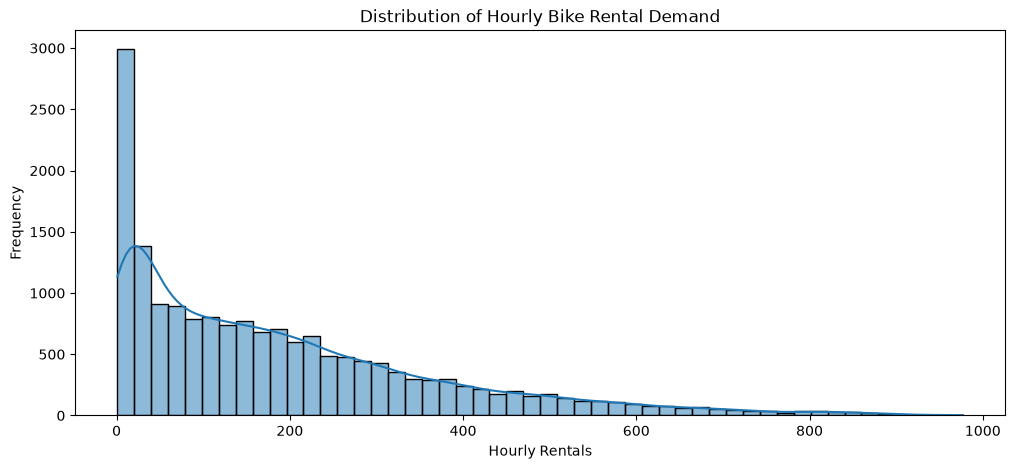

In [9]:
plt.figure(figsize=(12, 5))

sns.histplot(
    data=df,
    x="cnt",
    bins=50,
    kde=True
)

plt.title("Distribution of Hourly Bike Rental Demand")
plt.xlabel("Hourly Rentals")
plt.ylabel("Frequency")

hourly_cv = df["cnt"].std() / df["cnt"].mean()
daily_cv = df_dteday["cnt"].std() / df_dteday["cnt"].mean()

print(f"Hourly CV: {hourly_cv:.2%}")
print(f"Daily CV: {daily_cv:.2%}")

plt.show()

In [10]:
df["dteday"] = pd.to_datetime(df["dteday"])

df["datetime"] = (
    df["dteday"] +
    pd.to_timedelta(df["hr"], unit="h")
)

print("Duplicate timestamps:",
      df["datetime"].duplicated().sum())

expected_hours = pd.date_range(
    start=df["datetime"].min(),
    end=df["datetime"].max(),
    freq="h"
)

missing_hours = expected_hours.difference(df["datetime"])

print("Expected hourly records:", len(expected_hours))
print("Actual hourly records:", len(df))
print("Missing hourly records:", len(missing_hours))

Duplicate timestamps: 0
Expected hourly records: 17544
Actual hourly records: 17379
Missing hourly records: 165
